# 02 — Data Cleaning and Exploratory Data Analysis

**Data:** RECON-SL monthly billing panel (Oct 2022 – Oct 2024), Wave 1 survey (household level), 15-minute smart-meter
summaries. **Unit:** all consumption values are **kWh** (verified in notebook 01).

**Important reading notes**
* `month` is the **billing month**; the energy was mostly used in the *previous* calendar month (notebook 01, §4).
* Wave 1 was collected Dec 2023 – Oct 2024. Comparisons between Wave 1 characteristics and consumption are
  **descriptive associations**, not causal effects.
* RECON-SL covers households in LECO's service areas along Sri Lanka's western/south-western coast — results describe
  this sample, not all Sri Lankan households.

**Inputs** are produced by reproducible scripts:
`scripts/build_processed_data.py` (cleaning + Wave 1 aggregation) and `scripts/build_smart_meter_summaries.py`.

**Sections:** 1 Overview · 2 Cleaning decisions · 3 Consumption analysis · 4 Household characteristics ·
5 Smart-meter analysis · 6 Relationships · 7 Summary of findings

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import plot_style as ps
from src.data_loader import load_monthly_consumption, CONSUMPTION_UNIT as U
ps.apply()
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
P = ROOT / "data" / "processed"

raw = load_monthly_consumption()                              # parsed raw panel (comma fix applied)
m = pd.read_parquet(P / "monthly_clean.parquet")              # cleaned panel with flags
hh = pd.read_parquet(P / "household_features_w1.parquet")     # Wave 1, one row per household
log = json.loads((P / "cleaning_log.json").read_text())
obs = m[~m.is_missing].copy()                                 # observed (non-missing) household-months
hh_mean = obs.groupby("household_ID").consumption.mean().rename("mean_kwh")
H = hh.merge(hh_mean, left_on="household_ID", right_index=True, how="inner")  # households in cleaned panel
print("Unit:", U, "| cleaned panel:", m.shape, "| households with features + consumption:", len(H))

Unit: kWh | cleaned panel: (101200, 7) | households with features + consumption: 4048


## 1. Dataset overview
### 1.1 Dimensions, types, missing values and duplicates

In [2]:
overview = pd.DataFrame({
    "dataset": ["Monthly panel (raw, parsed)", "Monthly panel (cleaned)", "Wave 1 household features"],
    "rows": [len(raw), len(m), len(hh)],
    "columns": [raw.shape[1], m.shape[1], hh.shape[1]],
    "households": [raw.household_ID.nunique(), m.household_ID.nunique(), hh.household_ID.nunique()],
})
display(overview)
print("Cleaned panel dtypes:"); display(m.dtypes.to_frame("dtype").T)
print("Duplicate (household, month) rows in cleaned panel:", m.duplicated(["household_ID", "month"]).sum())
print("Duplicate household rows in Wave 1 features:", hh.household_ID.duplicated().sum())
print(f"Missing consumption in cleaned panel: {m.consumption.isna().sum()} ({m.consumption.isna().mean():.2%})")

,dataset,rows,columns,households
0,"Monthly panel (raw, parsed)",101575,3,4063
1,Monthly panel (cleaned),101200,7,4048
2,Wave 1 household features,4063,51,4063


Cleaned panel dtypes:


,household_ID,month,consumption,is_low_activity_household,is_missing,is_zero,is_isolated_spike
dtype,str,datetime64[us],float64,bool,bool,bool,bool


Duplicate (household, month) rows in cleaned panel: 0
Duplicate household rows in Wave 1 features: 0
Missing consumption in cleaned panel: 571 (0.56%)


### 1.2 Feature descriptions

In [3]:
desc = {
 "household_ID": "Pseudonymous household identifier (linkage/grouping only, not a model input)",
 "month": "Billing month (first day of month)", "consumption": f"Billed electricity consumption ({U}) — TARGET",
 "household_size": "Number of household members (W1)", "floor_area_sqft": "Floor area in square feet (W1)",
 "monthly_expenditure_lkr": "Total household expenditure last month, LKR (W1)",
 "socio_economic_class": "Socio-economic class A (highest) – E (W1)", "house_type": "Type of house (W1)",
 "built_year": "Construction period of the house (W1)", "csc_area": "LECO customer service centre area (W1)",
 "meter_type": "Smart / non-smart meter (W1)", "tenure": "Owned / rented / rent-free (W1)",
 "n_ac": "Number of air conditioners (AC roster)", "ac_hours_per_week": "Total AC hours last week (AC roster)",
 "n_fans": "Number of fans (fan roster)", "n_bulbs": "Number of bulbs (light roster)",
 "share_led_bulbs": "Share of bulbs that are LED", "n_refrigerator": "Number of refrigerators (appliance roster)",
 "n_appliances_total": "Total listed appliances", "has_solar": "Generates solar electricity (1/0)",
 "water_heating": "Water-heating method for bathing", "cooks_with_grid_electricity": "Uses grid electricity for cooking (1/0)",
 "n_children_under_15": "Members aged < 15", "n_elderly_60_plus": "Members aged ≥ 60",
 "mean_hours_at_home_per_week": "Average hours members stayed at home last week",
}
pd.DataFrame({"description": desc}).rename_axis("feature")

,description
feature,
household_ID,Pseudonymous household identifier (linkage/gro...
month,Billing month (first day of month)
consumption,Billed electricity consumption (kWh) — TARGET
household_size,Number of household members (W1)
floor_area_sqft,Floor area in square feet (W1)
monthly_expenditure_lkr,"Total household expenditure last month, LKR (W1)"
socio_economic_class,Socio-economic class A (highest) – E (W1)
house_type,Type of house (W1)
built_year,Construction period of the house (W1)


In [4]:
miss = hh.isna().sum(); miss = miss[miss > 0]
print("Wave 1 features with missing values (after skip-logic encoding):"); display(miss.to_frame("missing").T)
hh.describe().T[["count", "mean", "50%", "max"]].round(2)

Wave 1 features with missing values (after skip-logic encoding):


,floor_area_sqft,monthly_expenditure_lkr,share_led_bulbs
missing,26,135,9


,count,mean,50%,max
household_size,4063.0,4.00443,4.0,13.0
floor_area_sqft,4037.0,1356.181151,1000.0,9000.0
no_of_electricity_meters,4063.0,1.076298,1.0,7.0
monthly_expenditure_lkr,3928.0,71327.253055,60000.0,275000.0
has_home_business,4063.0,0.045779,0.0,1.0
has_renters_on_same_meter,4063.0,0.025597,0.0,1.0
n_children_under_15,4063.0,0.67684,0.0,5.0
n_elderly_60_plus,4063.0,0.833374,1.0,4.0
mean_hours_at_home_per_week,4063.0,125.135828,130.333333,168.0
n_employed,4063.0,1.347034,1.0,12.0


### 1.3 Household coverage across months

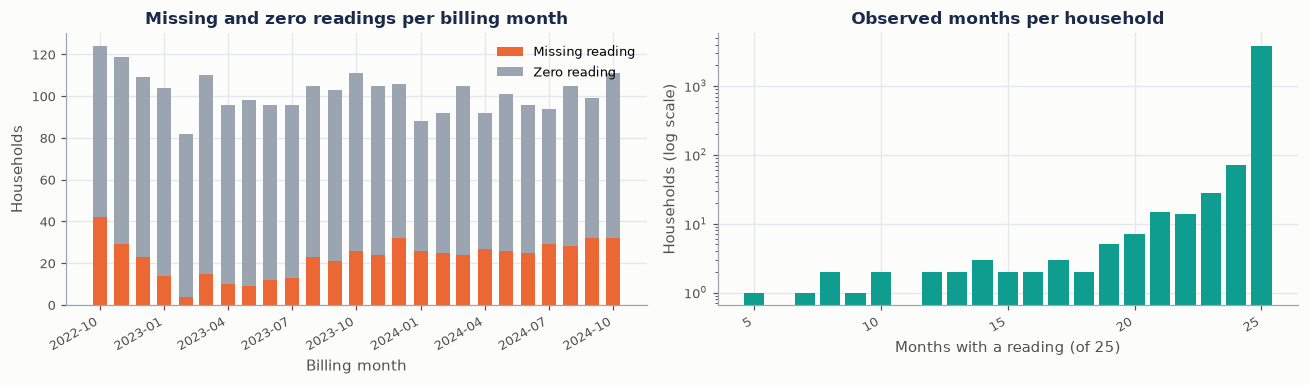

Households observed in all 25 months: 3885 of 4048


In [5]:
per_month = m.groupby("month").agg(observed=("consumption", lambda s: s.notna().sum()),
                                   missing=("is_missing", "sum"), zero=("is_zero", "sum"))
months_obs = obs.groupby("household_ID").size()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].bar(per_month.index, per_month.missing, width=20, color=ps.ORANGE, label="Missing reading")
ax[0].bar(per_month.index, per_month.zero, width=20, bottom=per_month.missing, color=ps.MUTED, label="Zero reading")
ax[0].set(title="Missing and zero readings per billing month", xlabel="Billing month", ylabel="Households")
ax[0].legend(); fig.autofmt_xdate()
vc = months_obs.value_counts().sort_index()
ax[1].bar(vc.index, vc.values, color=ps.TEAL)
ax[1].set_yscale("log"); ax[1].set(title="Observed months per household", xlabel="Months with a reading (of 25)", ylabel="Households (log scale)")
plt.tight_layout(); plt.show()
print(f"Households observed in all 25 months: {(months_obs == 25).sum()} of {len(months_obs)}")

**Observation.** Missing and zero readings are spread across all billing months (no month is systematically missing).
3,885 of 4,048 households (96%) have a reading in all 25 months, so the panel is close to complete. The panel is
balanced in rows; gaps appear only as missing *values*.

### 1.4 Descriptive statistics of consumption

In [6]:
obs.consumption.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(1).to_frame(f"consumption ({U})").T

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
consumption (kWh),100629.0,122.6,122.2,0.0,0.0,12.0,60.0,97.0,148.0,306.0,577.0,3025.0


## 2. Cleaning decisions (with evidence)

Rules are implemented in `src/data_processing.py`. Each rule was chosen from the evidence below, not by default.

In [7]:
pd.Series(log).to_frame("value")

,value
input_rows,101575
input_households,4063
missing_readings_in_input,590
always_zero_households_removed_invalid,15
low_activity_households_kept_and_flagged,19
output_rows,101200
output_households,4048
missing_readings_kept_as_nan,571
zero_months_kept,1976
isolated_spikes_flagged,18


### 2.1 Are zero readings 'missed' meter readings that are caught up later?

In [8]:
w = raw.pivot(index="household_ID", columns="month", values="consumption")
p, n = w.shift(1, axis=1), w.shift(-1, axis=1)
iso_zero = (w == 0) & (p > 0) & (n > 0)
ratio = (n / p)[iso_zero].stack()
print("Isolated single zero months (non-zero on both sides):", int(iso_zero.sum().sum()))
print(f"Next month / previous month around an isolated zero: median = {ratio.median():.2f}; "
      f"share where next month > 1.5× previous = {(ratio > 1.5).mean():.1%}")

Isolated single zero months (non-zero on both sides): 299
Next month / previous month around an isolated zero: median = 1.00; share where next month > 1.5× previous = 0.1%


If zeros were missed readings, the following bill would contain two months of usage (ratio ≈ 2). It does not
(median ≈ 1). **Decision:** keep zero months as genuine zero-usage bills.

**Always-zero and very-low households.** 15 households are exactly zero in every recorded month, and a further 19 never
exceed 5 kWh. **Decision:** remove only the **15 always-zero households**, as **invalid records**. Notebook 03
§1 verifies that all of them were occupied homes with a refrigerator in Wave 1, and that their linked smart meters
(where available) also read 0 kWh/day, so the meter linked to them is not their real supply. The 19 very-low
households are **kept** and flagged (`is_low_activity_household`); robustness experiment R1 excludes all 34.

In [9]:
mx = raw.groupby("household_ID").consumption.max()
print({f"max month ≤ {t} kWh": int((mx <= t).sum()) for t in [0, 1, 2, 5, 10, 20]})

{'max month ≤ 0 kWh': 15, 'max month ≤ 1 kWh': 19, 'max month ≤ 2 kWh': 25, 'max month ≤ 5 kWh': 34, 'max month ≤ 10 kWh': 44, 'max month ≤ 20 kWh': 76}


### 2.2 Extreme values — data errors or genuine high consumption?

Household-months above 5× that household's median: 227
Of those, preceded by a missing/zero month: 15
Strictly isolated spikes flagged (>4× both neighbours and >200 kWh above them): 18


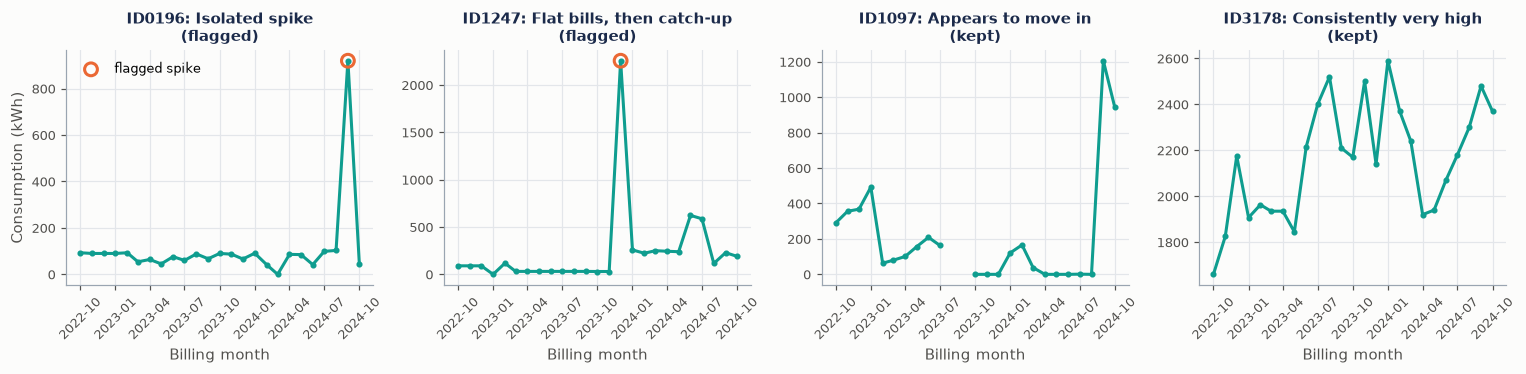

In [10]:
rel = w.div(w.where(w > 0).median(axis=1), axis=0)
print("Household-months above 5× that household's median:", int((rel > 5).sum().sum()))
print("Of those, preceded by a missing/zero month:", int(((rel > 5) & (p.isna() | p.eq(0)) & (w.columns > w.columns[0])).sum().sum()))
print("Strictly isolated spikes flagged (>4× both neighbours and >200 kWh above them):", int(m.is_isolated_spike.sum()))
examples = {"ID0196": "Isolated spike\n(flagged)", "ID1247": "Flat bills, then catch-up\n(flagged)",
            "ID1097": "Appears to move in\n(kept)", "ID3178": "Consistently very high\n(kept)"}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5), sharex=True)
for ax, (hid, title) in zip(axes, examples.items()):
    s = raw[raw.household_ID == hid].set_index("month").consumption
    f = m[(m.household_ID == hid) & m.is_isolated_spike].set_index("month").consumption
    ax.plot(s.index, s.values, color=ps.TEAL, marker="o", markersize=3)
    ax.scatter(f.index, f.values, s=70, facecolor="none", edgecolor=ps.ORANGE, linewidth=2, label="flagged spike", zorder=3)
    ax.set(title=f"{hid}: {title}", xlabel="Billing month"); ax.title.set_fontsize(9.5)
    ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel(f"Consumption ({U})"); axes[0].legend(loc="upper left")
plt.tight_layout(); plt.show()

Most very high values belong to households that are high *every* month or that change level for several months
(moving in, new appliances). Removing them would delete real behaviour. **Decision:** keep all extreme values; flag only
the strictly isolated spikes for a sensitivity analysis in notebook 07. The flag uses the following month, so it is a
retrospective label and is **never** used as a model feature.

**Missing readings** remain missing (never set to 0). Rows with a missing target cannot be used as training targets;
lag features handle earlier missing months explicitly.

## 3. Electricity consumption analysis
### 3.1 Distribution of monthly consumption

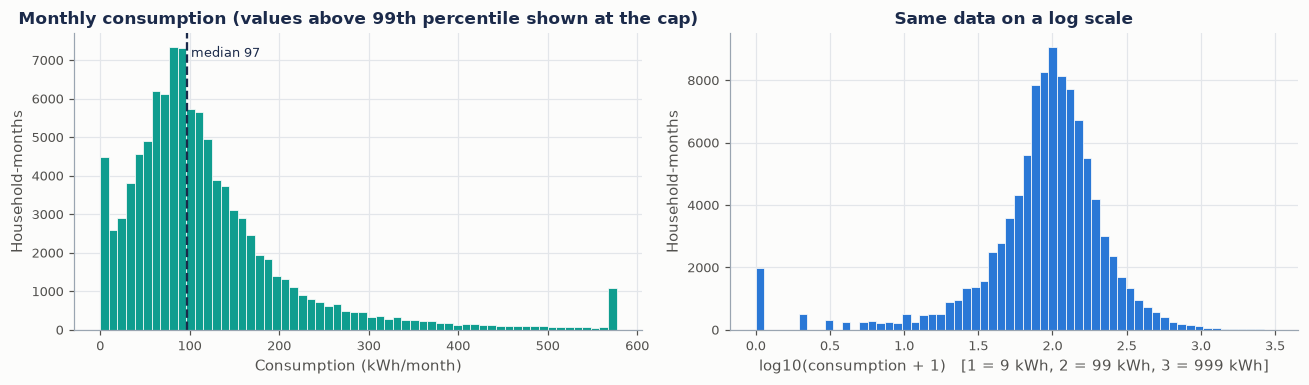

Skewness: 5.59 | mean 122.6 vs median 97.0 kWh


In [11]:
x = obs.consumption
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(x.clip(upper=x.quantile(.99)), bins=60, color=ps.TEAL, edgecolor=ps.SURFACE, linewidth=0.5)
ax[0].axvline(x.median(), color=ps.NAVY, lw=1.5, ls="--"); ax[0].text(x.median(), ax[0].get_ylim()[1]*0.92, f" median {x.median():.0f}", color=ps.NAVY, fontsize=8.5)
ax[0].set(title="Monthly consumption (values above 99th percentile shown at the cap)", xlabel=f"Consumption ({U}/month)", ylabel="Household-months")
ax[1].hist(np.log10(x + 1), bins=60, color=ps.BLUE, edgecolor=ps.SURFACE, linewidth=0.5)
ax[1].set(title="Same data on a log scale", xlabel=f"log10(consumption + 1)   [1 = 9 {U}, 2 = 99 {U}, 3 = 999 {U}]", ylabel="Household-months")
plt.tight_layout(); plt.show()
print(f"Skewness: {x.skew():.2f} | mean {x.mean():.1f} vs median {x.median():.1f} {U}")

**Observation.** Monthly consumption is strongly right-skewed (skewness ≈ 5.6; mean 123 kWh vs median 97 kWh). Half of
household-months are between 60 and 148 kWh, but a long tail reaches ~3,000 kWh. On a log scale the distribution is
close to symmetric.

**Modelling implication.** RMSE will be dominated by the few very large households; MAE is more representative of a
typical household. A log-transformed target is worth testing in notebook 04 (predictions must still be reported in kWh).

### 3.2 Monthly average, median and trend

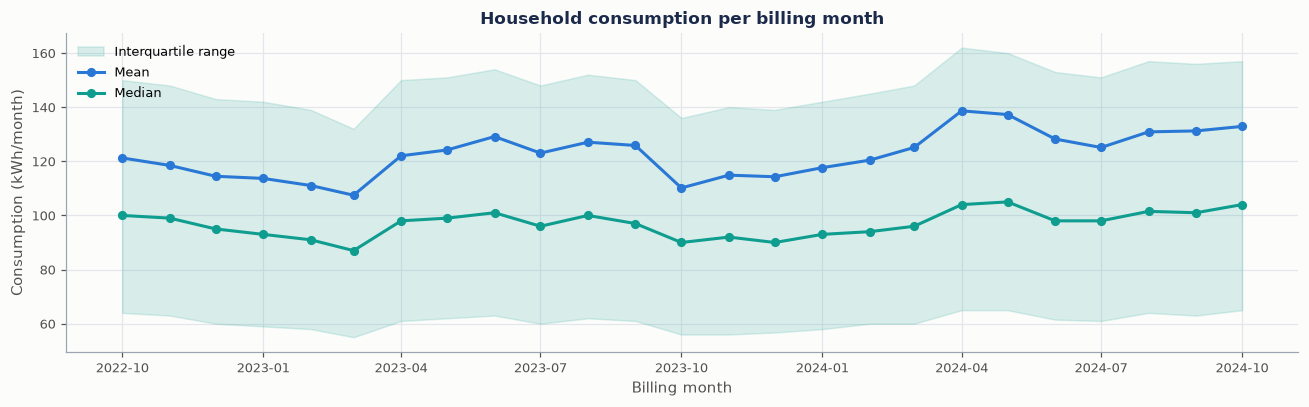

month,2022-10-01,2022-11-01,2022-12-01,2023-01-01,2023-02-01,2023-03-01,2023-04-01,2023-05-01,2023-06-01,2023-07-01,2023-08-01,2023-09-01,2023-10-01,2023-11-01,2023-12-01,2024-01-01,2024-02-01,2024-03-01,2024-04-01,2024-05-01,2024-06-01,2024-07-01,2024-08-01,2024-09-01,2024-10-01
mean,121.2,118.5,114.5,113.7,111.1,107.5,122.0,124.2,129.1,123.0,127.1,125.9,110.2,114.9,114.3,117.6,120.4,125.1,138.7,137.3,128.2,125.1,130.9,131.2,132.9
median,100.0,99.0,95.0,93.0,91.0,87.0,98.0,99.0,101.0,96.0,100.0,97.0,90.0,92.0,90.0,93.0,94.0,96.0,104.0,105.0,98.0,98.0,101.5,101.0,104.0
q25,64.0,63.0,60.0,59.0,58.0,55.0,61.0,62.0,63.0,60.0,62.0,61.0,56.0,56.0,56.8,58.0,60.0,60.0,65.0,65.0,61.5,61.0,64.0,63.0,65.0
q75,150.0,148.0,143.0,142.0,139.0,132.0,150.0,151.0,154.0,148.0,152.0,150.0,136.0,140.0,139.0,142.0,145.0,148.0,162.0,160.0,153.0,151.0,157.0,156.0,157.0


In [12]:
g = obs.groupby("month").consumption
stats = pd.DataFrame({"mean": g.mean(), "median": g.median(), "q25": g.quantile(.25), "q75": g.quantile(.75)})
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.fill_between(stats.index, stats.q25, stats.q75, color=ps.TEAL, alpha=0.15, label="Interquartile range")
ax.plot(stats.index, stats["mean"], color=ps.BLUE, marker="o", label="Mean")
ax.plot(stats.index, stats["median"], color=ps.TEAL, marker="o", label="Median")
ax.set(title="Household consumption per billing month", xlabel="Billing month", ylabel=f"Consumption ({U}/month)")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()
stats.round(1).T

### 3.3 Year-over-year comparison by calendar month

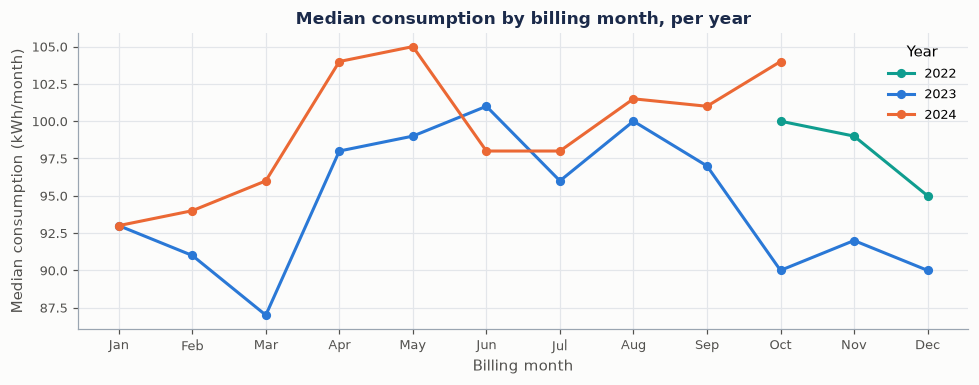

year,2022,2023,2024
mon,,,
1,NaN,93.0,93.0
2,NaN,91.0,94.0
3,NaN,87.0,96.0
4,NaN,98.0,104.0
5,NaN,99.0,105.0
6,NaN,101.0,98.0
7,NaN,96.0,98.0
8,NaN,100.0,102.0
9,NaN,97.0,101.0


In [13]:
yo = obs.assign(year=obs.month.dt.year, mon=obs.month.dt.month).groupby(["year", "mon"]).consumption.median().unstack(0)
fig, ax = plt.subplots(figsize=(9, 3.6))
for col, c in zip(yo.columns, ps.SERIES):
    ax.plot(yo.index, yo[col], marker="o", color=c, label=str(col))
ax.set_xticks(range(1, 13)); ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set(title="Median consumption by billing month, per year", xlabel="Billing month", ylabel=f"Median consumption ({U}/month)")
ax.legend(title="Year"); plt.tight_layout(); plt.show()
yo.round(0)

**Observation.** Month-to-month differences in the median are small (≈ 87–105 kWh). The highest medians are in billing
months April–May 2024 (104–105 kWh), which — because bills lag usage by about a month — reflect usage in roughly
March–April. Medians in 2024 are higher than in the same billing month of 2023 for most months (e.g. October: 90 → 105
kWh). 2023 is lowest in March (87 kWh).

**Caution.** With only two years, these patterns cannot be separated reliably from one-off events (weather, tariff
revisions, economic conditions in 2023). They are described here, not explained. A calendar-month feature may still
help, but its effect must be validated on the held-out months.

### 3.4 Variation between households

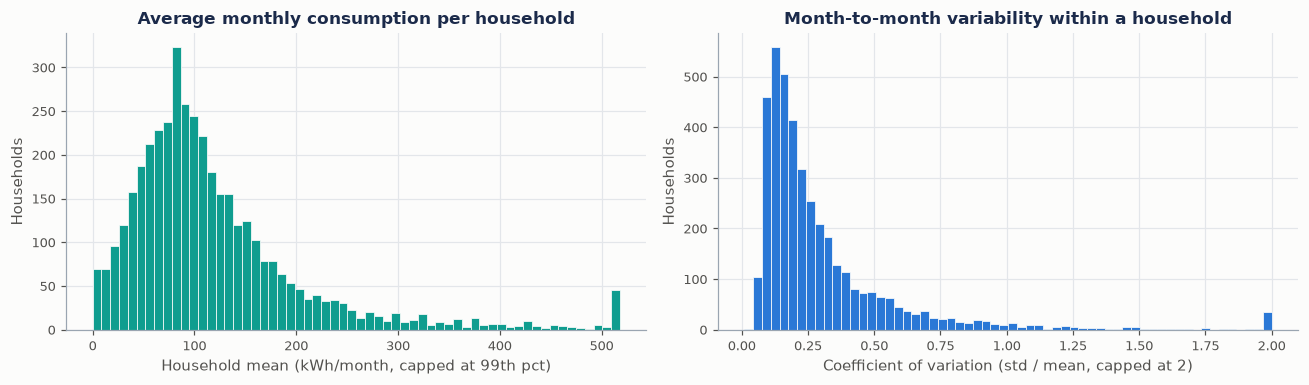

Variance of household means (between) = 12,771 | average within-household variance = 2,337
Share of total variance explained by which household it is: 84.5%
Median household CV: 0.21


In [14]:
hstats = obs.groupby("household_ID").consumption.agg(["mean", "std", "median", "min", "max", "count"])
hstats["cv"] = hstats["std"] / hstats["mean"].replace(0, np.nan)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(hstats["mean"].clip(upper=hstats["mean"].quantile(.99)), bins=60, color=ps.TEAL, edgecolor=ps.SURFACE, linewidth=0.5)
ax[0].set(title="Average monthly consumption per household", xlabel=f"Household mean ({U}/month, capped at 99th pct)", ylabel="Households")
ax[1].hist(hstats["cv"].dropna().clip(upper=2), bins=60, color=ps.BLUE, edgecolor=ps.SURFACE, linewidth=0.5)
ax[1].set(title="Month-to-month variability within a household", xlabel="Coefficient of variation (std / mean, capped at 2)", ylabel="Households")
plt.tight_layout(); plt.show()
between = hstats["mean"].var(); within = obs.groupby("household_ID").consumption.var().mean()
print(f"Variance of household means (between) = {between:,.0f} | average within-household variance = {within:,.0f}")
print(f"Share of total variance explained by which household it is: {between / (between + within):.1%}")
print(f"Median household CV: {hstats.cv.median():.2f}")

**Observation.** About **85% of the variance** in monthly consumption is *between* households (which household it is),
and only ~15% is month-to-month variation *within* a household. The median household's coefficient of variation is
0.21 — a typical household's bill moves about ±21% around its own average.

**Modelling implication.** Knowing a household's own past level is the single most valuable piece of information. This
is why lag/rolling features are expected to dominate, and why predicting *unseen* households (no history) will be much
harder.

### 3.5 Highest and lowest consumption

In [15]:
print("Highest single household-months:")
display(obs.nlargest(8, "consumption")[["household_ID", "month", "consumption", "is_isolated_spike"]])
print("Households with the highest / lowest average consumption:")
display(pd.concat([hstats.nlargest(5, "mean"), hstats.nsmallest(5, "mean")])[["mean", "median", "min", "max", "count"]].round(1))

Highest single household-months:


,household_ID,month,consumption,is_isolated_spike
68678,ID2759,2023-01-01,3025.0,False
90249,ID3624,2024-10-01,2629.0,False
79165,ID3178,2024-01-01,2590.0,False
16423,ID0661,2024-09-01,2587.0,True
79160,ID3178,2023-08-01,2520.0,False
79163,ID3178,2023-11-01,2500.0,False
79173,ID3178,2024-09-01,2480.0,False
79159,ID3178,2023-07-01,2400.0,False


Households with the highest / lowest average consumption:


,mean,median,min,max,count
household_ID,,,,,
ID3178,2154.4,2175.0,1660.0,2590.0,25
ID3885,1704.3,1749.0,983.0,2147.0,24
ID3624,1494.0,1389.0,462.0,2629.0,25
ID0395,1355.8,1399.0,0.0,1771.0,25
ID1521,1319.7,1245.0,731.0,2069.0,25
ID0677,0.0,0.0,0.0,1.0,25
ID0874,0.0,0.0,0.0,1.0,25
ID2124,0.1,0.0,0.0,2.0,25
ID2478,0.1,0.0,0.0,1.0,25


### 3.6 Changes between consecutive months

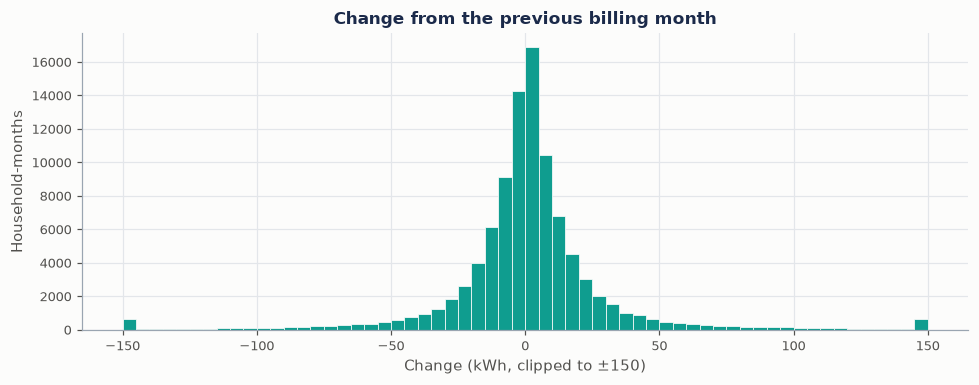

Median absolute change: 9 kWh | 90th percentile: 41 kWh
Share of months within ±20 kWh of the previous month: 75.5%


In [16]:
o = m.sort_values(["household_ID", "month"]).copy()
o["prev"] = o.groupby("household_ID").consumption.shift(1)
o["change"] = o.consumption - o.prev
ch = o.change.dropna()
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(ch.clip(-150, 150), bins=60, color=ps.TEAL, edgecolor=ps.SURFACE, linewidth=0.5)
ax.set(title="Change from the previous billing month", xlabel=f"Change ({U}, clipped to ±150)", ylabel="Household-months")
plt.tight_layout(); plt.show()
print(f"Median absolute change: {ch.abs().median():.0f} {U} | 90th percentile: {ch.abs().quantile(.9):.0f} {U}")
print(f"Share of months within ±20 {U} of the previous month: {(ch.abs() <= 20).mean():.1%}")

### 3.7 Household consumption patterns over time

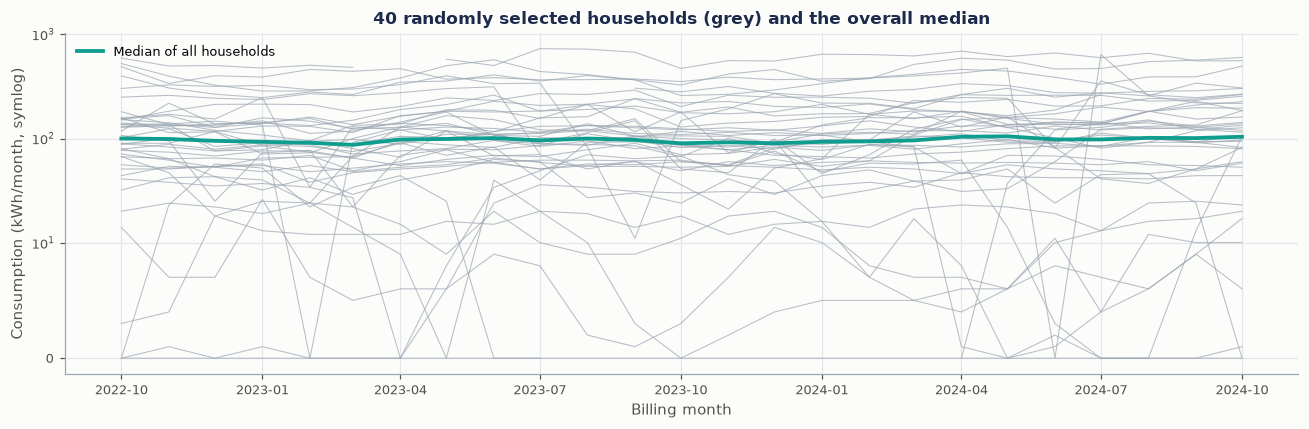

In [17]:
rng = np.random.default_rng(42)
sample = rng.choice(obs.household_ID.unique(), 40, replace=False)
wide = m.pivot(index="month", columns="household_ID", values="consumption")
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(wide.index, wide[sample], color=ps.MUTED, lw=0.7, alpha=0.7)
ax.plot(wide.index, wide.median(axis=1), color=ps.TEAL, lw=2.5, label="Median of all households")
ax.set_yscale("symlog", linthresh=10)
ax.set(title="40 randomly selected households (grey) and the overall median", xlabel="Billing month", ylabel=f"Consumption ({U}/month, symlog)")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

**Observation.** Most households follow a stable level with modest fluctuations; the overall median barely moves. A few
households show regime changes (dropping to near zero for several months, or stepping up/down), consistent with
vacancy, moving, or changes in appliances. Month-to-month changes are small: the median absolute change is 9 kWh and
75% of months are within ±20 kWh of the previous month.

## 4. Household characteristics (Wave 1) and consumption

Consumption here is each household's **average monthly consumption** over the observed months. Box plots hide
outliers beyond the whiskers for readability (outliers are analysed in §6.4); `n` is the number of households.

In [18]:
def box_by(col, order=None, ax=None, title=None, xlabel=None, min_n=20):
    d = H[[col, "mean_kwh"]].dropna()
    order = order or sorted(d[col].unique())
    order = [o for o in order if (d[col] == o).sum() >= min_n]
    data = [d.loc[d[col] == o, "mean_kwh"] for o in order]
    ax.boxplot(data, showfliers=False, widths=0.55, patch_artist=True,
               boxprops=dict(facecolor=ps.TEAL, alpha=0.35, edgecolor=ps.TEAL),
               medianprops=dict(color=ps.NAVY, lw=2), whiskerprops=dict(color=ps.MUTED), capprops=dict(color=ps.MUTED))
    ax.set_xticks(range(1, len(order) + 1)); ax.set_xticklabels([f"{o}\nn={len(x)}" for o, x in zip(order, data)], fontsize=8)
    ax.set(title=title or col, xlabel=xlabel or col, ylabel=f"Mean consumption ({U}/month)")
    return pd.Series([x.median() for x in data], index=order)

### 4.1 Household size

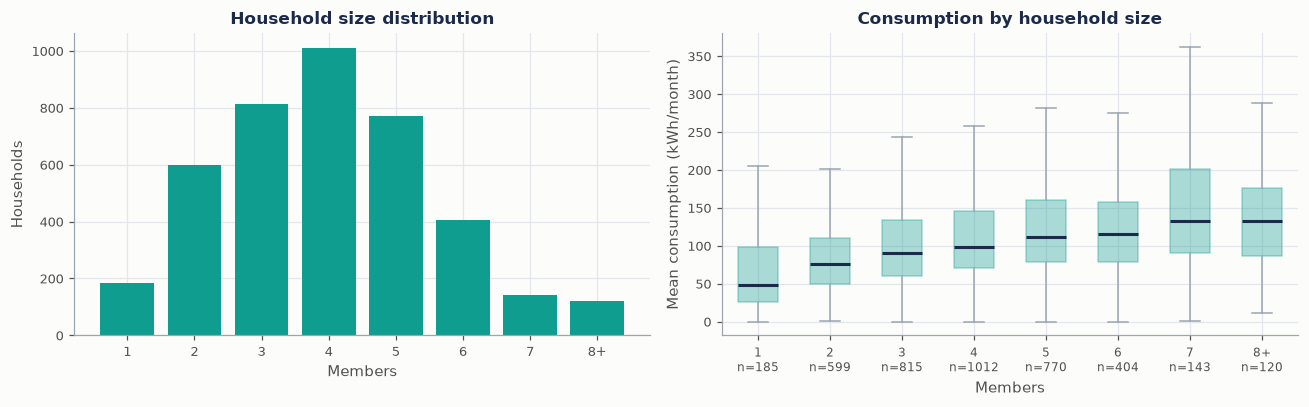

Median by size: {'1': 48.0, '2': 77.0, '3': 90.0, '4': 98.0, '5': 112.0, '6': 116.0, '7': 132.0, '8+': 132.0}


In [19]:
H["size_grp"] = H.household_size.clip(upper=8).astype(int).astype(str).replace("8", "8+")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
vc = H.size_grp.value_counts().reindex([str(i) for i in range(1, 8)] + ["8+"])
ax[0].bar(vc.index, vc.values, color=ps.TEAL); ax[0].set(title="Household size distribution", xlabel="Members", ylabel="Households")
med = box_by("size_grp", [str(i) for i in range(1, 8)] + ["8+"], ax=ax[1], title="Consumption by household size", xlabel="Members")
plt.tight_layout(); plt.show(); print("Median by size:", med.round(0).to_dict())

### 4.2 Appliance ownership

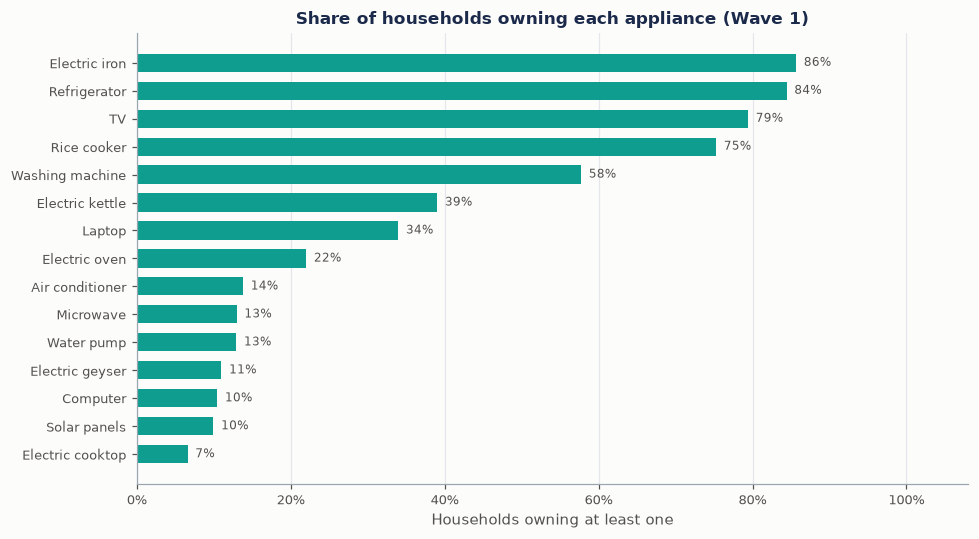

In [20]:
own = {"Refrigerator": "n_refrigerator", "TV": "n_tv", "Electric iron": "n_iron", "Rice cooker": "n_rice_cooker",
       "Washing machine": "n_washing_machine", "Laptop": "n_laptop", "Electric kettle": "n_kettle",
       "Air conditioner": "n_ac", "Electric oven": "n_oven", "Water pump": "n_water_pump", "Microwave": "n_microwave",
       "Electric geyser": "n_geyser", "Computer": "n_computer", "Electric cooktop": "n_cooktop", "Solar panels": "has_solar"}
rates = pd.Series({k: (H[v] > 0).mean() for k, v in own.items()}).sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(rates.index, rates.values, color=ps.TEAL, height=0.65)
for i, v in enumerate(rates.values): ax.text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=8, color=ps.INK_2)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_xlim(0, 1.08); ax.grid(axis="y", visible=False)
ax.set(title="Share of households owning each appliance (Wave 1)", xlabel="Households owning at least one", ylabel="")
plt.tight_layout(); plt.show()

### 4.3 Consumption by appliance ownership

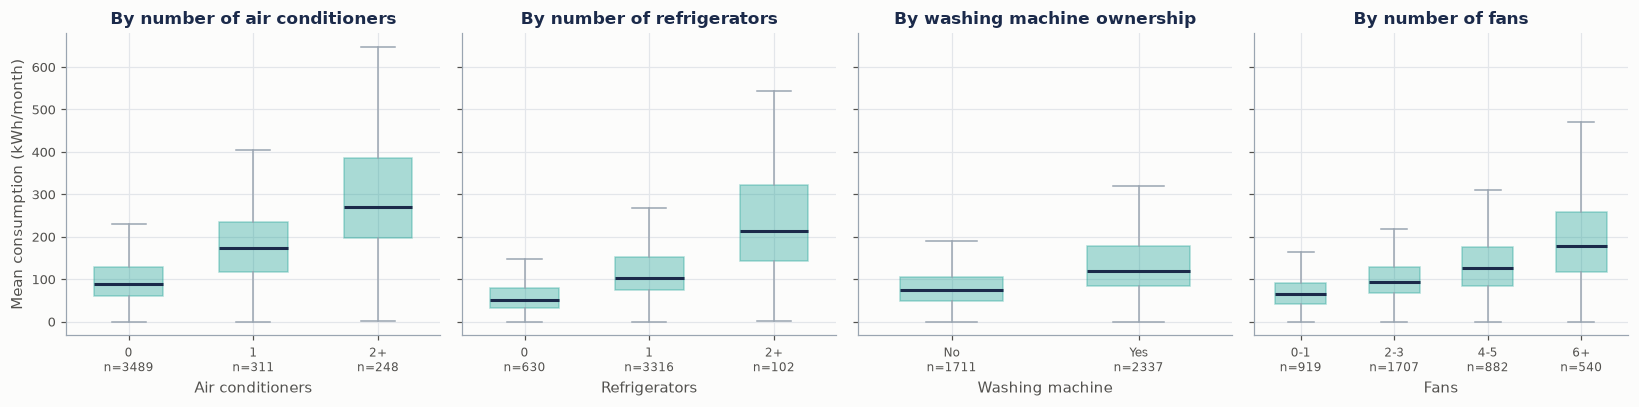

{'Air conditioners': {'0': 90.0, '1': 174.0, '2+': 269.0},
 'Refrigerators': {'0': 52.0, '1': 104.0, '2+': 214.0},
 'Washing machine': {'No': 76.0, 'Yes': 120.0},
 'Fans': {'0-1': 64.0, '2-3': 94.0, '4-5': 126.0, '6+': 177.0}}

In [21]:
H["Air conditioners"] = pd.cut(H.n_ac, [-1, 0, 1, 1000], labels=["0", "1", "2+"]).astype(str)
H["Refrigerators"] = pd.cut(H.n_refrigerator, [-1, 0, 1, 1000], labels=["0", "1", "2+"]).astype(str)
H["Washing machine"] = np.where(H.n_washing_machine > 0, "Yes", "No")
H["Fans"] = pd.cut(H.n_fans, [-1, 1, 3, 5, 1000], labels=["0-1", "2-3", "4-5", "6+"]).astype(str)
fig, ax = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
res = {}
for a, (col, order) in zip(ax, {"Air conditioners": ["0", "1", "2+"], "Refrigerators": ["0", "1", "2+"],
                               "Washing machine": ["No", "Yes"], "Fans": ["0-1", "2-3", "4-5", "6+"]}.items()):
    res[col] = box_by(col, order, ax=a, title=f"By number of {col.lower()}" if col != "Washing machine" else "By washing machine ownership", xlabel=col)
for a in ax[1:]: a.set_ylabel("")
plt.tight_layout(); plt.show()
{k: v.round(0).to_dict() for k, v in res.items()}

**Observation.** Appliance ownership shows clear, monotonic differences in typical consumption:

* Air conditioners — median 90 kWh (none), 174 kWh (one), 269 kWh (two or more).
* Refrigerators — 52 kWh (none), 104 kWh (one), 214 kWh (two or more).
* Washing machine — 76 kWh without vs 120 kWh with.
* Fans — rises from 64 kWh (0–1 fans) to 177 kWh (6+ fans).

**Caution.** These are associations. Households with more appliances are also larger and wealthier; the separate
effect of one appliance cannot be read from these charts.

### 4.4 Socio-economic class, expenditure and housing

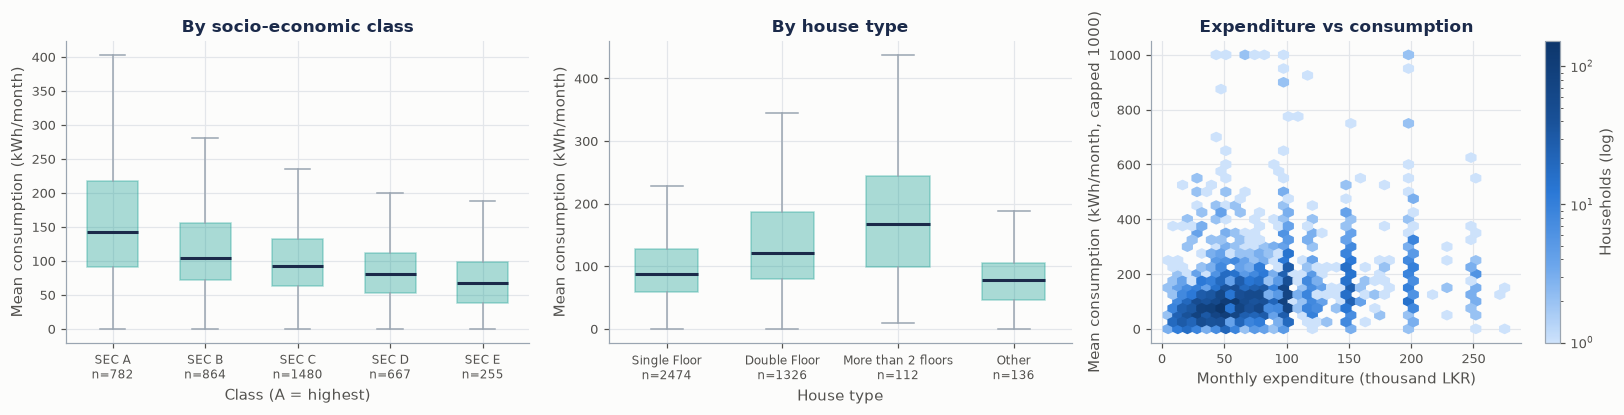

Median by SEC: {'SEC A': 142.0, 'SEC B': 104.0, 'SEC C': 92.0, 'SEC D': 81.0, 'SEC E': 67.0}
Median by house type: {'Single Floor': 88.0, 'Double Floor': 120.0, 'More than 2 floors': 167.0, 'Other': 79.0}


Spearman(expenditure, mean consumption) = 0.41
Income is not collected directly; expenditure and socio-economic class are the available proxies.


In [22]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
sec = box_by("socio_economic_class", ["SEC A", "SEC B", "SEC C", "SEC D", "SEC E"], ax=ax[0], title="By socio-economic class", xlabel="Class (A = highest)")
top_types = H.house_type.value_counts().index[:3].tolist()
H["house_type_grp"] = np.where(H.house_type.isin(top_types), H.house_type.str.replace("Single House - ", ""), "Other")
ht = box_by("house_type_grp", [t.replace("Single House - ", "") for t in top_types] + ["Other"], ax=ax[1], title="By house type", xlabel="House type")
d = H[["monthly_expenditure_lkr", "mean_kwh"]].dropna()
hb = ax[2].hexbin(d.monthly_expenditure_lkr / 1000, d.mean_kwh.clip(upper=1000), gridsize=35, cmap=ps.SEQUENTIAL, mincnt=1, bins="log")
ax[2].set(title="Expenditure vs consumption", xlabel="Monthly expenditure (thousand LKR)", ylabel=f"Mean consumption ({U}/month, capped 1000)")
fig.colorbar(hb, ax=ax[2], label="Households (log)"); plt.tight_layout(); plt.show()
print("Median by SEC:", sec.round(0).to_dict()); print("Median by house type:", ht.round(0).to_dict())
print(f"Spearman(expenditure, mean consumption) = {d.monthly_expenditure_lkr.corr(d.mean_kwh, method='spearman'):.2f}")
print("Income is not collected directly; expenditure and socio-economic class are the available proxies.")

**Observation.** Consumption increases steadily with socio-economic class (median 142 kWh for SEC A down to 67 kWh for
SEC E) and with house size (single floor 88 kWh → more than two floors 167 kWh). Expenditure has a moderate rank
correlation with consumption (Spearman ≈ 0.41). The expenditure hexbin shows vertical bands at round values (e.g.
50,000, 100,000, 150,000 LKR) — respondents rounded their answers, which limits its precision as a feature.

### 4.5 Consumption by LECO customer service centre (CSC) area

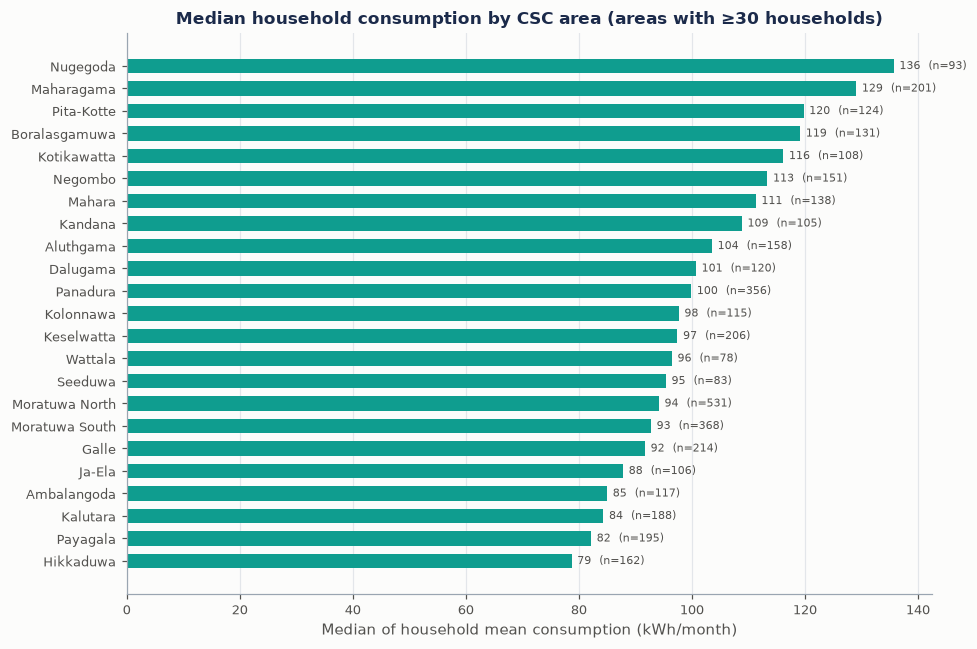

In [23]:
a = H.groupby("csc_area").mean_kwh.agg(["median", "size"]).query("size >= 30").sort_values("median")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(a.index.str.title(), a["median"], color=ps.TEAL, height=0.65); ax.grid(axis="y", visible=False)
for i, (v, n) in enumerate(zip(a["median"], a["size"])): ax.text(v + 1, i, f"{v:.0f}  (n={n})", va="center", fontsize=7.5, color=ps.INK_2)
ax.set(title="Median household consumption by CSC area (areas with ≥30 households)", xlabel=f"Median of household mean consumption ({U}/month)", ylabel="")
plt.tight_layout(); plt.show()

**Observation.** Median consumption differs by CSC area, from ~79 kWh (Hikkaduwa) to ~136 kWh (Nugegoda). Areas in and
around Colombo (Nugegoda, Maharagama, Pita-Kotte, Boralasgamuwa) are at the top; southern coastal areas (Hikkaduwa,
Payagala, Kalutara, Ambalangoda) at the bottom. Area is likely a proxy for urbanisation and income, not a cause.
Some areas have fewer than 100 households, so their medians are less certain.

## 5. Smart-meter analysis (15-minute data)

Built by `scripts/build_smart_meter_summaries.py`: interval kWh = difference of the cumulative register between two
readings exactly 15 minutes apart; negative differences (meter resets) and >10 kWh per 15 minutes are discarded; gaps
are **never** filled with zero. Hours are labelled by the interval **start** time (local time as recorded).

In [24]:
q = json.loads((P / "smart_interval_quality.json").read_text())
prof = pd.read_parquet(P / "smart_hourly_profile.parquet")
daily = pd.read_parquet(P / "smart_daily.parquet"); daily["date"] = pd.to_datetime(daily["date"])
cov = pd.read_parquet(P / "smart_coverage.parquet")
qq = pd.Series(q); display(qq.to_frame("count").T)
print(f"Valid share of consecutive reading pairs: {q['valid_intervals'] / q['consecutive_pairs']:.1%}")
print(f"Complete days (96 valid intervals): {q['complete_days']:,} of {q['days_total']:,} household-days with any data ({q['complete_days']/q['days_total']:.1%})")

,readings,consecutive_pairs,gap_not_15min,negative_register_change,over_10kwh_in_15min,valid_intervals,days_total,complete_days
count,45613280,45605284,97717,4174,4099,45499294,486035,404180


Valid share of consecutive reading pairs: 99.8%
Complete days (96 valid intervals): 404,180 of 486,035 household-days with any data (83.2%)


### 5.1 Coverage and missing intervals

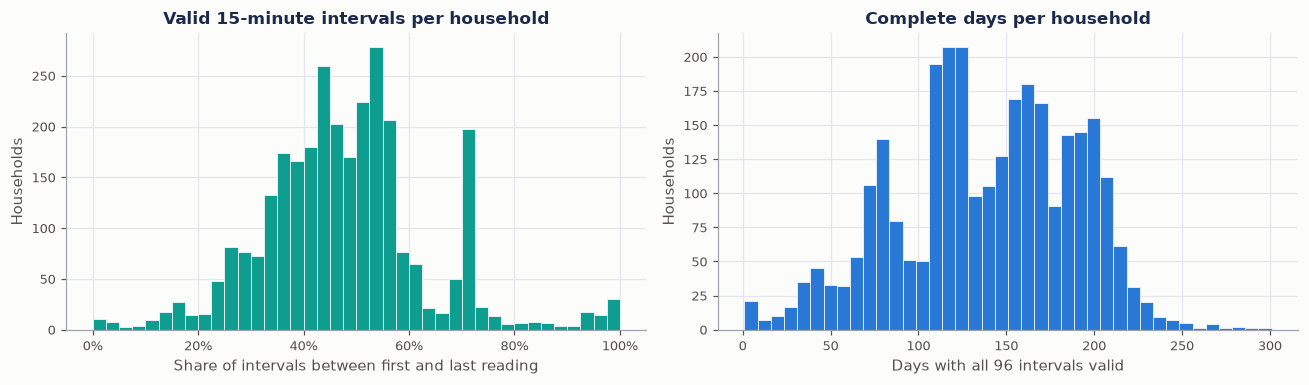

Smart-meter households: 2938 | also in the monthly/survey sample: 1424
Median valid-interval share: 47.1% | median complete days: 142
Households with ≥1 complete day, by month: {Period('2023-10', 'M'): 2161, Period('2023-11', 'M'): 2156, Period('2023-12', 'M'): 2298, Period('2024-01', 'M'): 820, Period('2024-03', 'M'): 291, Period('2024-04', 'M'): 2169, Period('2024-05', 'M'): 2098, Period('2024-06', 'M'): 2227, Period('2024-07', 'M'): 1676, Period('2024-08', 'M'): 2307, Period('2024-09', 'M'): 2134, Period('2024-10', 'M'): 2258, Period('2024-11', 'M'): 2135, Period('2024-12', 'M'): 1323}


In [25]:
cov["span_intervals"] = ((cov["last"] - cov["first"]) / pd.Timedelta(minutes=15)).clip(lower=1)
cov["valid_share"] = cov.valid_intervals / cov.span_intervals
days_per_hh = daily.groupby("household_ID").size()
in_panel = cov.household_ID.isin(m.household_ID)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(cov.valid_share.clip(upper=1), bins=40, color=ps.TEAL, edgecolor=ps.SURFACE, linewidth=0.5)
ax[0].xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax[0].set(title="Valid 15-minute intervals per household", xlabel="Share of intervals between first and last reading", ylabel="Households")
ax[1].hist(days_per_hh, bins=40, color=ps.BLUE, edgecolor=ps.SURFACE, linewidth=0.5)
ax[1].set(title="Complete days per household", xlabel="Days with all 96 intervals valid", ylabel="Households")
plt.tight_layout(); plt.show()
print(f"Smart-meter households: {len(cov)} | also in the monthly/survey sample: {in_panel.sum()}")
print(f"Median valid-interval share: {cov.valid_share.median():.1%} | median complete days: {days_per_hh.median():.0f}")
dc = daily.groupby(daily.date.dt.to_period("M")).household_ID.nunique()
print("Households with ≥1 complete day, by month:", dc.to_dict())

### 5.2 Usage across the day — weekday vs weekend

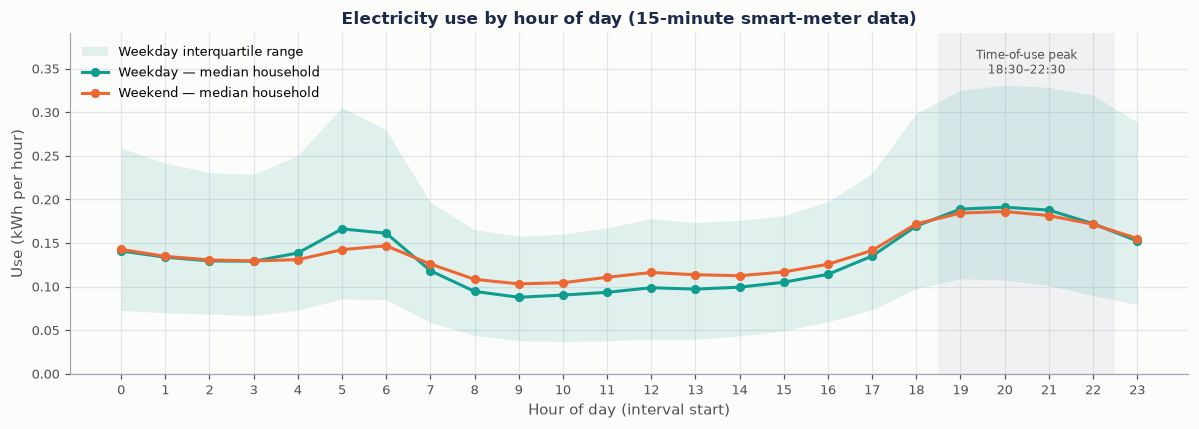

Mean vs median at 00:00 (weekday): [{'mean': 0.292, 'median': 0.141, 'q75': 0.259}] → the mean sits above the upper quartile at night: a minority of heavy users dominates the mean, so medians are plotted.
Peak hour of the median household (weekday): 20 | (weekend): 20
Share of the median weekday profile used in hours 18–21 (4 of 24 hours): 23.1%
Lowest hour (weekday): 9 | peak / trough ratio: 2.2


In [26]:
pp = prof[prof.n_intervals >= 40]          # at least 10 hours of data behind each household-hour value
agg = pp.groupby(["day_type", "hour"]).kwh_per_hour.agg(mean="mean", median="median", q25=lambda s: s.quantile(.25), q75=lambda s: s.quantile(.75)).reset_index()
wd = agg[agg.day_type == "Weekday"]
fig, ax = plt.subplots(figsize=(11, 4))
ax.axvspan(18.5, 22.5, color=ps.MUTED, alpha=0.12, lw=0)
ax.fill_between(wd.hour, wd.q25, wd.q75, color=ps.TEAL, alpha=0.12, lw=0, label="Weekday interquartile range")
for (dt, c) in zip(["Weekday", "Weekend"], [ps.TEAL, ps.ORANGE]):
    a = agg[agg.day_type == dt]
    ax.plot(a.hour, a["median"], color=c, marker="o", label=f"{dt} — median household")
ax.text(20.5, wd.q75.max() * 1.04, "Time-of-use peak\n18:30–22:30", fontsize=8, color=ps.INK_2, ha="center")
ax.set_ylim(0, wd.q75.max() * 1.18)
ax.set_xticks(range(0, 24)); ax.set(title="Electricity use by hour of day (15-minute smart-meter data)",
       xlabel="Hour of day (interval start)", ylabel=f"Use ({U} per hour)")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()
w_ = agg.pivot(index="hour", columns="day_type", values="median")
print("Mean vs median at 00:00 (weekday):", agg.query("day_type=='Weekday' and hour==0")[["mean", "median", "q75"]].round(3).to_dict("records"),
      "→ the mean sits above the upper quartile at night: a minority of heavy users dominates the mean, so medians are plotted.")
print("Peak hour of the median household (weekday):", int(w_.Weekday.idxmax()), "| (weekend):", int(w_.Weekend.idxmax()))
print(f"Share of the median weekday profile used in hours 18–21 (4 of 24 hours): {w_.Weekday.loc[18:21].sum() / w_.Weekday.sum():.1%}")
print(f"Lowest hour (weekday): {int(w_.Weekday.idxmin())} | peak / trough ratio: {w_.Weekday.max() / w_.Weekday.min():.1f}")

**Observation.** For the median household, electricity use is lowest around 09:00 and peaks at **20:00**, inside the
18:30–22:30 time-of-use peak window; the evening peak is about 2.2× the morning trough. Weekdays show an additional early
morning peak at 05:00–06:00 (getting ready for work/school) that is flatter at weekends, while weekend daytime use is
slightly higher. The mean household lies above the upper quartile at night — a minority of heavy users (e.g. night-time
air-conditioning) dominates averages, so medians are shown.

### 5.3 Daily consumption and weekday vs weekend

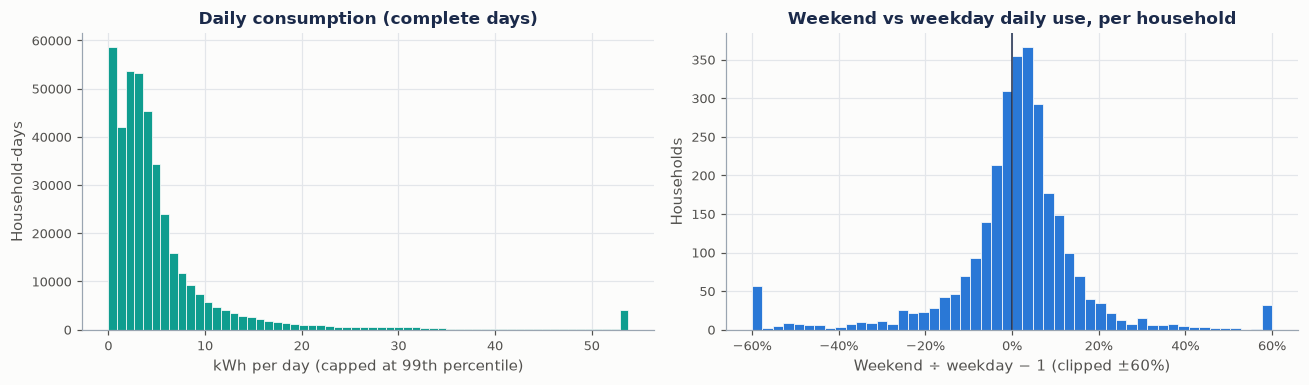

Median daily use: 3.49 kWh/day | household median weekend/weekday ratio: 1.019
Households using more at weekends: 59.7%


In [27]:
daily["day_type"] = np.where(daily.date.dt.day_of_week >= 5, "Weekend", "Weekday")
hd = daily.groupby(["household_ID", "day_type"]).kwh.mean().unstack().dropna()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(daily.kwh.clip(upper=daily.kwh.quantile(.99)), bins=60, color=ps.TEAL, edgecolor=ps.SURFACE, linewidth=0.5)
ax[0].set(title="Daily consumption (complete days)", xlabel=f"{U} per day (capped at 99th percentile)", ylabel="Household-days")
diff = (hd.Weekend / hd.Weekday.replace(0, np.nan) - 1).dropna()
ax[1].hist(diff.clip(-0.6, 0.6), bins=50, color=ps.BLUE, edgecolor=ps.SURFACE, linewidth=0.5); ax[1].axvline(0, color=ps.NAVY, lw=1)
ax[1].xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax[1].set(title="Weekend vs weekday daily use, per household", xlabel="Weekend ÷ weekday − 1 (clipped ±60%)", ylabel="Households")
plt.tight_layout(); plt.show()
print(f"Median daily use: {daily.kwh.median():.2f} {U}/day | household median weekend/weekday ratio: {(hd.Weekend / hd.Weekday).median():.3f}")
print(f"Households using more at weekends: {(diff > 0).mean():.1%}")

**Observation.** The median complete day uses ≈ 3.5 kWh (≈ 105 kWh per 30-day month — consistent with the median bill).
Weekend and weekday totals are almost the same (median weekend/weekday ratio ≈ 1.02); 60% of households use slightly
more at weekends. The difference is small compared with the differences *between* households, so a day-type effect is
not important for monthly prediction.

**Coverage caveat.** 15-minute data exist for 2,938 smart-meter households, but only 1,420 of them are in the
monthly/survey sample, and there are almost no complete days in January–March 2024 (none in February 2024). This
confirms the earlier decision to treat smart-meter data as an analysis supplement, not as a core model input.

### 5.4 Comparing measurement intervals on a common scale

Monthly bills, 6-hour and 15-minute data are not directly comparable. Here both are converted to **average kWh per day**:
the smart-meter value is the household's mean over complete days in calendar month *m*; the billed value is the bill
for billing month *m + 1* (which mostly covers calendar month *m*, notebook 01) divided by the days in month *m*.

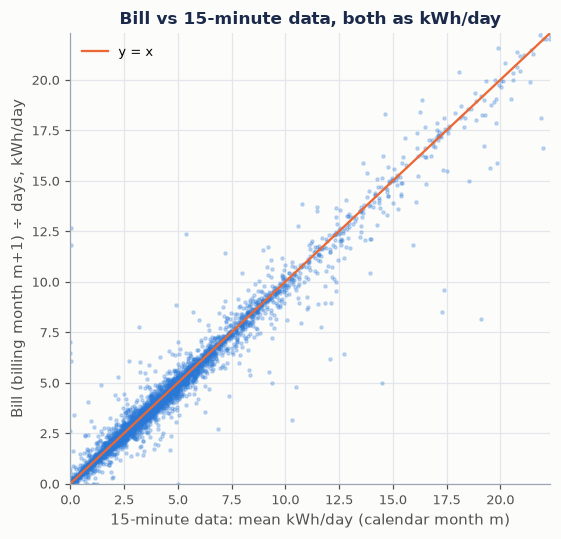

Household-months compared: 5,282 | Spearman = 0.977 | median ratio bill/smart = 0.994


In [28]:
dm = daily.assign(month=daily.date.dt.to_period("M").dt.to_timestamp()).groupby(["household_ID", "month"]).agg(smart_kwh_day=("kwh", "mean"), days=("kwh", "size")).reset_index()
dm = dm[dm.days >= 10]
bill = m[["household_ID", "month", "consumption"]].assign(month=lambda d: d.month - pd.offsets.MonthBegin(1))
cmp_ = dm.merge(bill, on=["household_ID", "month"]).dropna()
cmp_["bill_kwh_day"] = cmp_.consumption / cmp_.month.dt.days_in_month
lim = cmp_[["smart_kwh_day", "bill_kwh_day"]].quantile(.99).max()
fig, ax = plt.subplots(figsize=(5.2, 5))
ax.scatter(cmp_.smart_kwh_day, cmp_.bill_kwh_day, s=4, alpha=0.25, color=ps.BLUE)
ax.plot([0, lim], [0, lim], color=ps.ORANGE, lw=1.5, label="y = x"); ax.set(xlim=(0, lim), ylim=(0, lim))
ax.set(title="Bill vs 15-minute data, both as kWh/day", xlabel=f"15-minute data: mean {U}/day (calendar month m)", ylabel=f"Bill (billing month m+1) ÷ days, {U}/day")
ax.legend(); plt.tight_layout(); plt.show()
r = cmp_.bill_kwh_day / cmp_.smart_kwh_day.replace(0, np.nan)
print(f"Household-months compared: {len(cmp_):,} | Spearman = {cmp_.smart_kwh_day.corr(cmp_.bill_kwh_day, method='spearman'):.3f} | median ratio bill/smart = {r.median():.3f}")

**Observation.** When both are converted to kWh per day, bills and 15-minute data agree closely (Spearman ≈ 0.98,
median ratio ≈ 0.99, 5,268 household-months). This confirms that the three measurement intervals describe the same
energy once they are put on a common scale and the one-month billing lag is respected.

## 6. Relationship analysis
### 6.1 Previous consumption vs current consumption

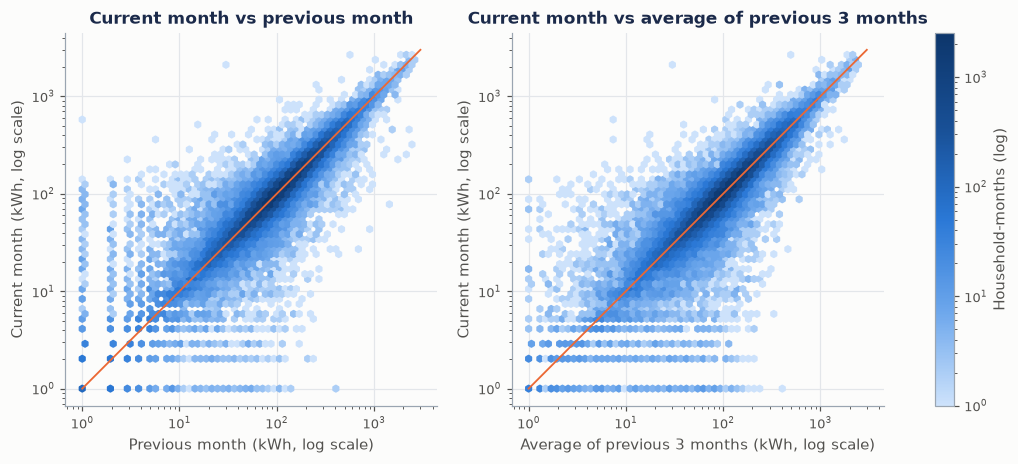

,predictor (past data only),n,Pearson r,Spearman ρ,MAE if used as forecast (kWh)
0,Previous month,96476,0.926,0.934,19.254
1,Mean of previous 3 months,92459,0.933,0.926,20.363
2,Mean of all earlier months,88485,0.916,0.890,25.044


In [29]:
o = m.sort_values(["household_ID", "month"]).copy()
g = o.groupby("household_ID").consumption
o["lag1"] = g.shift(1)
o["roll3_prev"] = g.transform(lambda s: s.shift(1).rolling(3, min_periods=2).mean())       # previous 3 months only
o["hist_mean_prev"] = g.transform(lambda s: s.shift(1).expanding(min_periods=3).mean())   # all earlier months only
d = o.dropna(subset=["consumption", "lag1"])
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
for a, col, ttl in zip(ax, ["lag1", "roll3_prev"], ["Previous month", "Average of previous 3 months"]):
    dd = o.dropna(subset=["consumption", col])
    dd = dd[(dd[col] > 0) & (dd.consumption > 0)]   # log scale: zeros cannot be drawn (they stay in the table below)
    hb = a.hexbin(dd[col], dd.consumption, gridsize=60, cmap=ps.SEQUENTIAL, mincnt=1, bins="log", xscale="log", yscale="log",
                  extent=(0, np.log10(3000), 0, np.log10(3000)))
    a.plot([1, 3000], [1, 3000], color=ps.ORANGE, lw=1.2)
    a.set(title=f"Current month vs {ttl.lower()}", xlabel=f"{ttl} ({U}, log scale)", ylabel=f"Current month ({U}, log scale)")
fig.colorbar(hb, ax=ax, label="Household-months (log)"); plt.show()
rows = []
for col, name in [("lag1", "Previous month"), ("roll3_prev", "Mean of previous 3 months"), ("hist_mean_prev", "Mean of all earlier months")]:
    dd = o.dropna(subset=["consumption", col])
    rows.append({"predictor (past data only)": name, "n": len(dd), "Pearson r": dd.consumption.corr(dd[col]),
                 "Spearman ρ": dd.consumption.corr(dd[col], method="spearman"),
                 f"MAE if used as forecast ({U})": (dd.consumption - dd[col]).abs().mean()})
pd.DataFrame(rows).round(3)

**Observation.** Past consumption is a very strong predictor of the current bill: correlation ≈ 0.93 with the previous
month and with the previous 3-month average. Simply repeating last month's bill would give an average error of about
**19 kWh** (descriptive, all months). The long-run historical mean is slightly weaker (MAE ≈ 25 kWh), suggesting recent
months matter more than the distant past. Points far from the diagonal are level changes and spikes — the cases where
models can add value over simple persistence.

_Note:_ zero months are hidden in log-scale hexbins (log of 0 is undefined); the correlation table includes them. The
"MAE if used as forecast" column is a simple descriptive benchmark computed on all months — the formal naive baseline
is evaluated on the held-out test period in notebook 04.

### 6.2 Household characteristics vs consumption

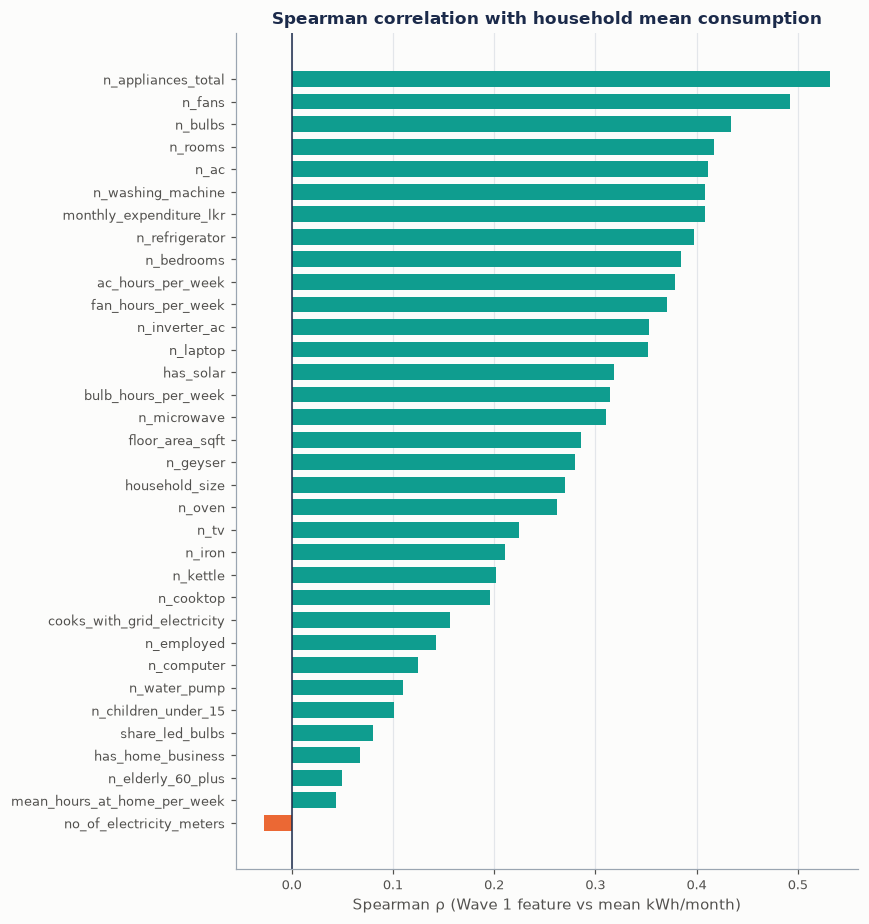

,n_appliances_total,n_fans,n_bulbs,n_rooms,n_ac,n_washing_machine,monthly_expenditure_lkr,n_refrigerator,n_bedrooms,ac_hours_per_week
Spearman ρ,0.532,0.493,0.434,0.417,0.412,0.408,0.408,0.397,0.384,0.379


In [30]:
num_cols = ["household_size", "floor_area_sqft", "monthly_expenditure_lkr", "n_ac", "ac_hours_per_week", "n_inverter_ac",
            "n_fans", "fan_hours_per_week", "n_bulbs", "bulb_hours_per_week", "share_led_bulbs", "n_rooms", "n_bedrooms",
            "n_refrigerator", "n_washing_machine", "n_tv", "n_iron", "n_kettle", "n_microwave", "n_oven", "n_cooktop",
            "n_geyser", "n_water_pump", "n_computer", "n_laptop", "n_appliances_total", "n_children_under_15",
            "n_elderly_60_plus", "n_employed", "mean_hours_at_home_per_week", "has_solar", "cooks_with_grid_electricity",
            "has_home_business", "no_of_electricity_meters"]
sp = H[num_cols].corrwith(H.mean_kwh, method="spearman").sort_values()
fig, ax = plt.subplots(figsize=(8, 8.5))
ax.barh(sp.index, sp.values, color=np.where(sp.values >= 0, ps.TEAL, ps.ORANGE), height=0.7)
ax.axvline(0, color=ps.NAVY, lw=1); ax.grid(axis="y", visible=False)
ax.set(title="Spearman correlation with household mean consumption", xlabel="Spearman ρ (Wave 1 feature vs mean kWh/month)", ylabel="")
plt.tight_layout(); plt.show()
sp.sort_values(ascending=False).head(10).round(3).to_frame("Spearman ρ").T

**Observation.** Among Wave 1 characteristics, the strongest rank correlations with average consumption are total
appliances (ρ ≈ 0.53), fans (0.49), bulbs (0.43), rooms (0.42), air conditioners (0.41), expenditure (0.41) and washing
machines (0.41). Household size is weaker (≈ 0.27). Solar ownership is *positively* correlated with consumption (≈ 0.32)
and with air-conditioner ownership (≈ 0.53): solar households tend to be larger, wealthier users, and the billed value
appears to be grid import rather than net of solar generation.

**Modelling implication.** Survey features are moderately informative about a household's *level* (useful for unseen
households), but much weaker than the household's own history (ρ ≈ 0.93). Whether they add accuracy *on top of* history
is the ablation question for notebook 07.

### 6.3 Correlation heatmap of numeric features

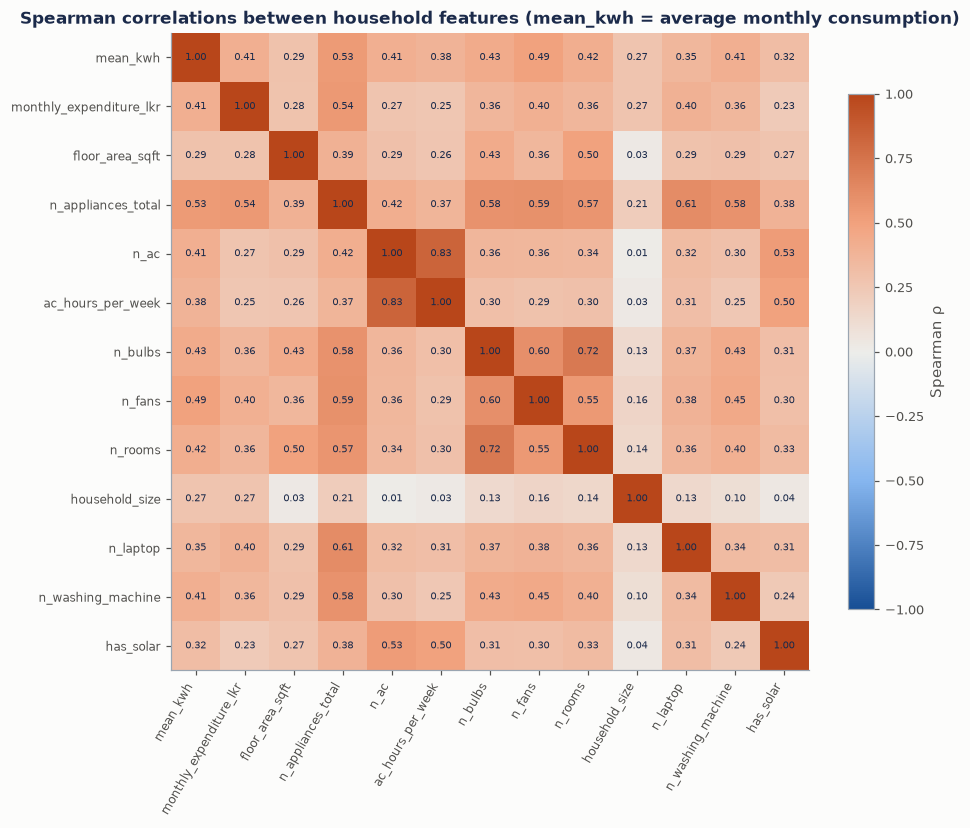

In [31]:
sel = ["mean_kwh", "monthly_expenditure_lkr", "floor_area_sqft", "n_appliances_total", "n_ac", "ac_hours_per_week",
       "n_bulbs", "n_fans", "n_rooms", "household_size", "n_laptop", "n_washing_machine", "has_solar"]
cm = H[sel].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(cm, cmap=ps.DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(sel))); ax.set_xticklabels(sel, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(sel))); ax.set_yticklabels(sel, fontsize=8); ax.grid(False)
for i in range(len(sel)):
    for j in range(len(sel)):
        ax.text(j, i, f"{cm.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6.5, color=ps.NAVY)
fig.colorbar(im, ax=ax, label="Spearman ρ", shrink=0.8)
ax.set_title("Spearman correlations between household features (mean_kwh = average monthly consumption)")
plt.tight_layout(); plt.show()

Spearman (rank) correlation is used because most counts and consumption are strongly right-skewed. Features that are
strongly correlated with each other (e.g. rooms, bulbs, floor area) carry overlapping information — relevant for
linear models and for interpreting feature importance.

### 6.4 Outlier analysis

In [32]:
q1, q3 = obs.consumption.quantile([.25, .75]); upper = q3 + 1.5 * (q3 - q1)
out = obs[obs.consumption > upper]
p95 = hstats["mean"].quantile(.95)
persist = out.household_ID.map(hstats["mean"]) > p95
print(f"IQR rule: upper fence = {upper:.0f} {U}; household-months above it: {len(out):,} ({len(out)/len(obs):.1%}) in {out.household_ID.nunique()} households")
print(f"Of those, belonging to households whose AVERAGE is in the top 5%: {persist.mean():.1%}")
print(f"Isolated spikes flagged: {int(m.is_isolated_spike.sum())} ({m.is_isolated_spike.sum()/len(out):.2%} of IQR outliers)")

IQR rule: upper fence = 280 kWh; household-months above it: 6,173 (6.1%) in 593 households
Of those, belonging to households whose AVERAGE is in the top 5%: 69.5%
Isolated spikes flagged: 18 (0.29% of IQR outliers)


**Observation.** By the usual box-plot (IQR) rule, 6.1% of household-months are "outliers" (> 280 kWh), but about 70%
of them belong to households whose *average* is in the top 5% — they are genuinely high consumers, not errors. Only 18
(0.3%) are isolated spikes. This supports keeping extreme values and treating only isolated spikes in a sensitivity
analysis.

## 7. Summary of findings

| # | Finding (from this notebook's outputs) | Implication for modelling |
|---|---|---|
| 1 | Cleaned panel: 4,048 households × 25 months; 0.56% missing; 15 invalid always-zero households removed (19 very-low households kept and flagged) | Train on observed targets only; never fill missing with 0 |
| 2 | Strong right skew (mean 123 vs median 97 kWh) | Report MAE as primary metric; test a log target |
| 3 | ~85% of variance is between households | Household history (lags, rolling means) will dominate; unseen households are much harder |
| 4 | Previous-month bill alone gives MAE ≈ 19 kWh | Include a naive persistence baseline — ensembles must beat it |
| 5 | Small seasonal movement; 2024 slightly above 2023 | Calendar-month feature optional; validate it on future months |
| 6 | Wave 1 features moderately related to consumption (ρ up to ≈ 0.53) | Test history-only vs history + survey (ablation) |
| 7 | Extreme values are mostly genuine high users; 18 isolated spikes | Keep extremes; sensitivity analysis without spikes |
| 8 | Evening peak at ~20:00; weekday/weekend nearly equal | Day-type not relevant for monthly prediction |
| 9 | Smart-meter data cover ~35% of sample households, with a gap in early 2024 | Keep smart-meter data out of the core model |